# 01 · Data

**Owner: Nahid** · Builds `data/daily.csv`, the one file every other notebook reads.

Downloads the S&P 500 index (^GSPC) OHLC, VIX, VIX3M from Yahoo Finance and the 3-month T-bill (DTB3) from FRED, then computes returns, realized variance and the variance risk premium. Conventions are documented at the top of `src/data.py`.

In [1]:
import sys; sys.path.append('..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.data import download_raw, build_daily, EPISODES

## Download

In [2]:
raw = download_raw(start='2004-01-01')   # one extra year so HAR inputs exist by 2005
raw.tail()

/Users/nahidhasansagar/Documents/The-Erdös-Institute/Quant-Finance-Final-Project/vrp-project/.venv/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/nahidhasansagar/Documents/The-Erdös-Institute/Quant-Finance-Final-Project/vrp-project/.venv/lib/python3.14/site-packages/yfinance/multi.py:220: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.rename(columns=ctx.isins, inplace=True)
/Users/nahidhasansagar/Documents/The-Erdös-Institute/Quant-Finance-Final-Project/vrp-project/.venv/lib/python3.14/site-packages/yfinance/multi.py:224: Pandas4Warning: The inp

,spx_open,spx_high,spx_low,spx_close,vix,vix3m,rf
date,,,,,,,
2026-10-27,7699.470215,7736.240234,7677.160156,7722.600098,17.520000,19.570000,0.0405
2026-10-28,7735.560059,7758.430176,7718.370117,7743.979980,16.910000,19.219999,0.0401
2026-10-29,7699.609863,7732.209961,7690.939941,7720.390137,17.200001,19.370001,0.0400
2026-10-30,7631.069824,7637.479980,7527.560059,7580.069824,19.420000,20.780001,0.0399
2026-11-02,7610.830078,7662.229980,7539.379883,7541.399902,21.150000,21.600000,0.0403


## Build the daily dataset

In [3]:
df = build_daily(raw)
df = df.loc['2005-01-01':]
print(df.shape)
df[['spx_close','vix','vix3m','rf','logret','iv_var','rv_fwd21','vrp']].describe().T

(5493, 17)


,count,mean,std,min,25%,50%,75%,max
spx_close,5493.0,2718.751036,1728.679991,676.530029,1334.430054,2081.340088,3855.760010,7818.930176
vix,5493.0,19.106228,8.509160,9.140000,13.540000,16.770000,21.930000,82.690002
vix3m,5107.0,21.199941,7.527536,11.030000,15.970000,19.530001,24.245000,72.980003
rf,5493.0,0.017859,0.019055,-0.000500,0.000900,0.009600,0.037000,0.053600
logret,5493.0,0.000333,0.011959,-0.127652,-0.004082,0.000720,0.005711,0.109572
iv_var,5493.0,0.043744,0.053888,0.008354,0.018333,0.028123,0.048092,0.683764
rv_fwd21,5472.0,0.036147,0.079815,0.001441,0.008878,0.016314,0.033268,0.913253
vrp,5472.0,0.007650,0.063360,-0.815953,0.004621,0.010888,0.021226,0.326924


## Checks before anyone uses it

Each check should print `True`. If one fails, fix it before moving on.

In [4]:
checks = {
    'no missing SPX/VIX': df[['spx_close','vix']].isna().sum().sum() == 0,
    'VIX in percent (10-90 typical)': df['vix'].between(5, 100).all(),
    'VIX3M starts around Dec 2007': df['vix3m'].first_valid_index() < pd.Timestamp('2008-01-31'),
    'rf in decimals': df['rf'].dropna().between(-0.01, 0.10).all(),
    'only the last 21 rows lack rv_fwd21': df['rv_fwd21'].isna().sum() == 21,
    'mean VIX^2 above mean RV (premium exists)': df['iv_var'].mean() > df['rv_fwd21'].mean(),
}
for k, v in checks.items(): print(f'{v!s:5}  {k}')

True   no missing SPX/VIX
True   VIX in percent (10-90 typical)
True   VIX3M starts around Dec 2007
True   rf in decimals
True   only the last 21 rows lack rv_fwd21
True   mean VIX^2 above mean RV (premium exists)


## Quick look

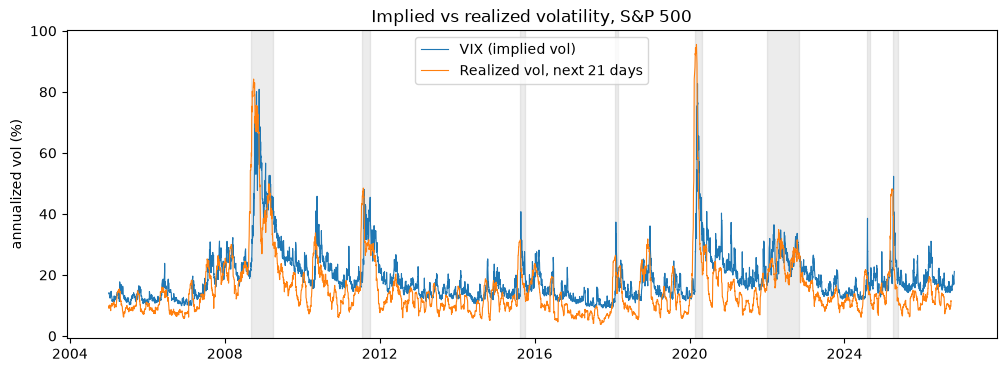

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df.index, 100*np.sqrt(df['iv_var']), label='VIX (implied vol)', lw=0.8)
ax.plot(df.index, 100*np.sqrt(df['rv_fwd21']), label='Realized vol, next 21 days', lw=0.8)
for name, (s, e) in EPISODES.items():
    ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), color='grey', alpha=0.15)
ax.set_ylabel('annualized vol (%)'); ax.legend(); ax.set_title('Implied vs realized volatility, S&P 500')
plt.show()

## Save

In [6]:
df.to_csv('../data/daily.csv')
print('saved', len(df), 'rows')

saved 5493 rows
